In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

token = userdata.get('GH_TOKEN')
![ -d /content/yuca_transfer ] || git clone https://{token}@github.com/Frank-Dev007/yuca_transfer.git /content/yuca_transfer
%cd /content/yuca_transfer
!git pull
!git config user.name "jdbcamilo"
!git config user.email "juancamilo0350@gmail.com"

!python scripts/preparar_datos.py
!python scripts/verificar_datos.py
!ls results docs

Mounted at /content/drive
Cloning into '/content/yuca_transfer'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (69/69), done.
remote: Total 81 (delta 30), reused 31 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 8.13 MiB | 20.54 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/content/yuca_transfer
Already up to date.
Copiando desde Drive...
Tamaño del zip (MB): 1354.1
Contenido de data/: ['cassavaleafdata.zip', 'cassavaleafdata']

train: 5656 imágenes (esperado 5656) -> OK
   cbb          466  (8.2%)
   cbsd        1443  (25.5%)
   cgm          773  (13.7%)
   cmd         2658  (47.0%)
   healthy      316  (5.6%)

validation: 1889 imágenes (esperado 1889) -> OK
   cbb          156  (8.3%)
   cbsd         482  (25.5%)
   cgm          258  (13.7%)
   cmd          887  (47.0%)
   healthy      106  (5.6%)

test: 1885 imágenes (esperado 1885) -> OK
   cbb          155  (8.2%)
   cbsd         4

In [2]:
%%writefile src/data.py
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

CLASES = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
CLASE_A_IDX = {c: i for i, c in enumerate(CLASES)}
MEDIA = [0.485, 0.456, 0.406]   # normalización de ImageNet (protocolo)
DESV = [0.229, 0.224, 0.225]

# Decisión 3 del protocolo: lado corto a 256 y recorte central de 224
transform_base = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
transform_modelo = transforms.Compose([transform_base, transforms.ToTensor(),
                                       transforms.Normalize(MEDIA, DESV)])

# E4 (experimento adicional): augmentation moderado SOLO para train.
# Sin cambios de color, para no alterar el aspecto de los síntomas.
transform_aumentado = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESV),
])

class YucaDataset(Dataset):
    def __init__(self, tabla, transform):
        self.rutas = tabla["ruta"].tolist()
        self.etiquetas = [CLASE_A_IDX[c] for c in tabla["clase"]]
        self.transform = transform

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert("RGB")
        return self.transform(img), self.etiquetas[i]

def cargar_particiones(csv="results/particiones_finales.csv"):
    df = pd.read_csv(csv)
    return {s: df[df.split == s].reset_index(drop=True) for s in ["train", "validation", "test"]}

def crear_dataloaders(batch_size=32, seed=42, transform=transform_modelo,
                      transform_train=None, num_workers=2):
    particiones = cargar_particiones()
    generador = torch.Generator().manual_seed(seed)
    loaders = {}
    for split, tabla in particiones.items():
        t = transform_train if (split == "train" and transform_train is not None) else transform
        loaders[split] = DataLoader(
            YucaDataset(tabla, t), batch_size=batch_size,
            shuffle=(split == "train"),
            generator=generador if split == "train" else None,
            num_workers=num_workers, pin_memory=True)
    return loaders

Writing src/data.py


In [3]:
%%writefile src/evaluate.py
import json, os
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from src.data import CLASES

def calcular_metricas(y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=range(5), target_names=CLASES,
                                output_dict=True, zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", labels=range(5), zero_division=0)),
        "por_clase": {c: {"precision": rep[c]["precision"], "recall": rep[c]["recall"],
                          "f1": rep[c]["f1-score"], "soporte": int(rep[c]["support"])} for c in CLASES},
    }

def imprimir_metricas(m, nombre):
    print(f"{nombre}: accuracy = {m['accuracy']:.4f} | macro-F1 = {m['macro_f1']:.4f}")
    for c, v in m["por_clase"].items():
        print(f"   {c:8s} recall = {v['recall']:.3f}   F1 = {v['f1']:.3f}   (n = {v['soporte']})")

def guardar_matriz_confusion(y_true, y_pred, ruta, titulo):
    cm = confusion_matrix(y_true, y_pred, labels=range(5))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    plt.tight_layout()
    plt.savefig(ruta, dpi=150)
    plt.show()
    return cm

def guardar_json(datos, ruta):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    with open(ruta, "w") as f:
        json.dump(datos, f, indent=2, ensure_ascii=False)

Writing src/evaluate.py


In [4]:
import sys, os, time, pickle
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
sys.path.append("/content/yuca_transfer")

from src.utils import fijar_semilla
from src.data import cargar_particiones, transform_base, CLASE_A_IDX
from src.evaluate import calcular_metricas, imprimir_metricas, guardar_matriz_confusion, guardar_json

SEED = 42
fijar_semilla(SEED)
particiones = cargar_particiones()
print({s: len(t) for s, t in particiones.items()})

{'train': 5616, 'validation': 1878, 'test': 1874}


In [5]:
BINS = 32   # protocolo, decisión 12

def histograma_color(ruta):
    img = transform_base(Image.open(ruta).convert("RGB"))   # resize 256 + recorte 224
    arr = np.asarray(img)                                    # 224 x 224 x 3, valores de 0 a 255
    canales = [np.histogram(arr[:, :, c], bins=BINS, range=(0, 256))[0] for c in range(3)]
    return np.concatenate(canales) / (224 * 224)             # proporción de píxeles por intervalo

X, y = {}, {}
t0 = time.time()
for split, tabla in particiones.items():
    X[split] = np.stack([histograma_color(r) for r in tqdm(tabla.ruta, desc=split)])
    y[split] = np.array([CLASE_A_IDX[c] for c in tabla.clase])
t_extraccion = time.time() - t0
n_total = sum(len(v) for v in y.values())
print({s: X[s].shape for s in X})
print(f"Extracción: {t_extraccion:.1f} s en total, {t_extraccion / n_total * 1000:.1f} ms por imagen")

train:   0%|          | 0/5616 [00:00<?, ?it/s]

validation:   0%|          | 0/1878 [00:00<?, ?it/s]

test:   0%|          | 0/1874 [00:00<?, ?it/s]

{'train': (5616, 96), 'validation': (1878, 96), 'test': (1874, 96)}
Extracción: 88.8 s en total, 9.5 ms por imagen


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED))
t0 = time.time()
modelo.fit(X["train"], y["train"])
t_entrenamiento = time.time() - t0
print(f"Tiempo de entrenamiento: {t_entrenamiento:.2f} s")

Tiempo de entrenamiento: 2.45 s


In [7]:
m_val = calcular_metricas(y["validation"], modelo.predict(X["validation"]))
imprimir_metricas(m_val, "Validación")
print()

t0 = time.time()
pred_test = modelo.predict(X["test"])
t_inferencia_ms = (time.time() - t0) / len(X["test"]) * 1000
m_test = calcular_metricas(y["test"], pred_test)
imprimir_metricas(m_test, "Test")
print(f"\nInferencia del clasificador: {t_inferencia_ms:.4f} ms por imagen "
      f"(+ {t_extraccion / n_total * 1000:.1f} ms de extracción del histograma)")

Validación: accuracy = 0.5501 | macro-F1 = 0.2921
   cbb      recall = 0.119   F1 = 0.188   (n = 151)
   cbsd     recall = 0.438   F1 = 0.472   (n = 479)
   cgm      recall = 0.019   F1 = 0.036   (n = 257)
   cmd      recall = 0.898   F1 = 0.700   (n = 886)
   healthy  recall = 0.038   F1 = 0.065   (n = 105)

Test: accuracy = 0.5491 | macro-F1 = 0.2997
   cbb      recall = 0.110   F1 = 0.173   (n = 154)
   cbsd     recall = 0.419   F1 = 0.450   (n = 477)
   cgm      recall = 0.032   F1 = 0.057   (n = 253)
   cmd      recall = 0.901   F1 = 0.706   (n = 885)
   healthy  recall = 0.067   F1 = 0.112   (n = 105)

Inferencia del clasificador: 0.0038 ms por imagen (+ 9.5 ms de extracción del histograma)


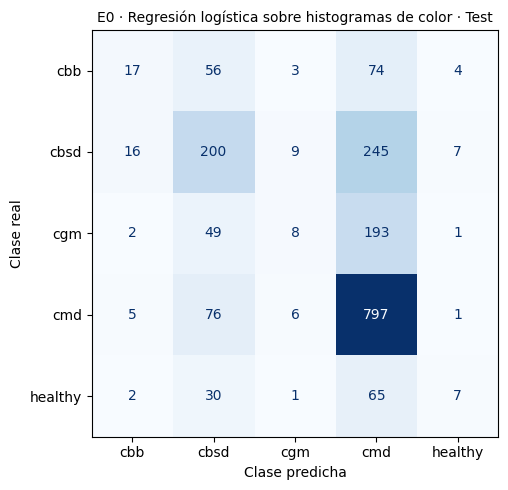

{
  "experimento": "E0",
  "modelo": "Regresión logística sobre histogramas de color (32 intervalos x 3 canales)",
  "semilla": 42,
  "validacion": {
    "accuracy": 0.5500532481363152,
    "macro_f1": 0.2920925733208491,
    "por_clase": {
      "cbb": {
        "precision": 0.43902439024390244,
        "recall": 0.11920529801324503,
        "f1": 0.1875,
        "soporte": 151
      },
      "cbsd": {
        "precision": 0.5109489051094891,
        "recall": 0.4384133611691023,
        "f1": 0.47191011235955055,
        "soporte": 479
      },
      "cgm": {
        "precision": 0.2631578947368421,
        "recall": 0.019455252918287938,
        "f1": 0.036231884057971016,
        "soporte": 257
      },
      "cmd": {
        "precision": 0.5730741540676746,
        "recall": 0.8984198


In [8]:
import pandas as pd
from src.data import CLASES

os.makedirs("results/E0", exist_ok=True)
guardar_matriz_confusion(y["test"], pred_test, "results/E0/matriz_confusion_test.png",
                         "E0 · Regresión logística sobre histogramas de color · Test")

pd.DataFrame({"ruta": particiones["test"].ruta,
              "real": [CLASES[i] for i in y["test"]],
              "predicha": [CLASES[i] for i in pred_test]}).to_csv("results/E0/predicciones_test.csv", index=False)

with open("results/E0/modelo_e0.pkl", "wb") as f:
    pickle.dump(modelo, f)

reg = modelo[-1]
guardar_json({
    "experimento": "E0",
    "modelo": "Regresión logística sobre histogramas de color (32 intervalos x 3 canales)",
    "semilla": SEED,
    "validacion": m_val,
    "test": m_test,
    "tiempo_extraccion_ms_por_imagen": t_extraccion / n_total * 1000,
    "tiempo_entrenamiento_s": t_entrenamiento,
    "tiempo_inferencia_clasificador_ms_por_imagen": t_inferencia_ms,
    "parametros": int(reg.coef_.size + reg.intercept_.size),
    "tamano_modelo_kb": os.path.getsize("results/E0/modelo_e0.pkl") / 1024,
}, "results/E0/metricas.json")
print(open("results/E0/metricas.json").read()[:800])

In [ ]:
!git pull
!git add src results/E0
!git commit -m "Pipeline de datos y evaluación; E0 baseline ejecutado"
!git push

In [ ]:
!cp "/content/drive/MyDrive/Colab Notebooks/02_E0_baseline.ipynb" notebooks/
!git add notebooks/02_E0_baseline.ipynb
!git commit -m "Notebook E0"
!git push